# WICOS: hand-crafted features
The feature models (logistic regression, SVM on features, random forest) do not get the 128 × 128 pixels but a short list of **hand-crafted features** that describe the *motion*: how fast the hand moves, how wide the spread of velocities is and how that changes over time. They are computed by `extract_features` in `src/features.py`; `prepare_data.py` saves them in the dataset as `X_feat`.

This notebook explains how the features are computed, shows them for example samples, and then **critically checks** which features can be trusted: do they describe the gesture, or the person or recording? Everything that is learned or checked here uses the **training samples only**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut, PredefinedSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, str(Path("../src").resolve()))
import features as F
from preprocessing import NOISE_MARGIN
from prepare_data import GESTURES, OUT_DIR, SEED, load_data, split

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(exist_ok=True)

spectrograms, metadata = load_data()
idx_train, idx_test, cv_fold = split(metadata)
labels, persons = metadata.label.to_numpy(), metadata.person.to_numpy()
y_train, groups_train = labels[idx_train], persons[idx_train]

## Gesture power
All features are computed on the **gesture power** at the original time resolution (no resizing, so the duration is kept). The spectrogram $S$ (dB) is first cleaned with the same per-sample noise floor $f = \operatorname{median}(S) + 7.9$ dB as the images (`remove_noise`, see `preprocessing.ipynb`), cropped to the same Doppler window, converted to linear power, and the power of the floor is subtracted:

$$P(d, t) = 10^{\max(S(d,t),\, f)/10} - 10^{f/10}$$

with $d$ the Doppler bin relative to zero Doppler (bin 400) and $t$ the time bin. Linear power is used because the papers weight the Doppler bins by their power; noise below the floor gets weight 0. There is no fixed dB threshold: the noise level differs by 15-20 dB between persons (see `data_exploration.ipynb`), so a fixed threshold would keep the noise of some recordings and remove the gesture of others.

**Active time bins.** Before and after the gesture, a time bin contains only a few noise pixels that survived the floor; their power-weighted centroid and envelopes jump randomly over the whole Doppler axis. Time bins whose total power is below 5% of the strongest time bin are therefore skipped for all per-time-bin curves.

## The features
**1. Doppler centroid and bandwidth** (Fioranelli et al., 2016, Sec. 3.2). The centroid is the power-weighted mean Doppler per time bin (the average velocity of the hand), the bandwidth the power-weighted spread around it (how many different velocities occur at once):

$$f_c(t) = \frac{\sum_d d\, P(d,t)}{\sum_d P(d,t)}, \qquad B(t) = \sqrt{\frac{\sum_d \big(d - f_c(t)\big)^2 P(d,t)}{\sum_d P(d,t)}}$$

The paper uses the mean of $f_c(t)$ and of $B(t)$ as features; following the assignment ("their statistical moments"), we use the mean, standard deviation, skewness and kurtosis of both curves over time (8 features), plus the **crossing rate** of the centroid through its mean per 100 time bins (a wave moves back and forth).

**2. Envelopes** (after Amin et al., 2019). The paper's own envelope (the outermost Doppler cell above a threshold $\sigma E(n)$, with the curves themselves as features) is implemented and evaluated in `envelope_features.ipynb`; on DopNet it is sensitive to single noise cells. Here a more robust definition based on the cumulative power is used: per time bin, the Doppler bin below which a share $q$ of the power lies, for $q = 0.05$ (lower), $0.5$ (central) and $0.95$ (upper envelope). They follow the outline of the signature: the highest velocity towards and away from the radar. Features: mean and standard deviation of each envelope, the maximum of the upper and minimum of the lower envelope, and the mean and maximum spread between upper and lower envelope (10 features).

**3. Doppler spectrum** (time-averaged gesture power): the **extent** (Doppler bins between 1% and 99% of the cumulative power), the **positive power ratio** (share of the power at positive Doppler: towards the radar), the **entropy** (how spread out the spectrum is), and the **occupancy** (share of time-Doppler cells above the noise floor).

**4. Time:** the recording length (`duration`), the number of active time bins (`active_duration`), and how bursty the energy over time is (`time_energy_std`, `time_half_power_ratio`: share of active time bins with more than half the peak power).

This gives 27 features.

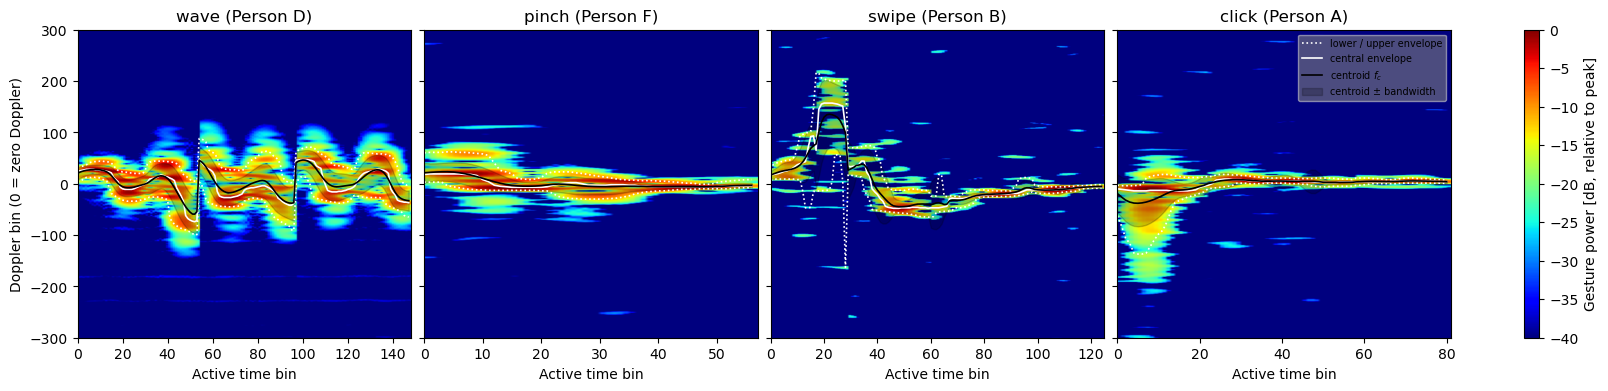

In [2]:
# The curves behind the features, for one training sample per gesture
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True, constrained_layout=True)
doppler = F.doppler_axis()
for ax, (k, g) in zip(axes, enumerate(GESTURES)):
    i = idx_train[y_train == k][0]
    P = F.gesture_power(spectrograms[i])
    P = P[:, F.active_bins(P)]
    env = F.envelopes(P, doppler)
    fc, bw = F.centroid_bandwidth(P, doppler)
    t = np.arange(P.shape[1])

    im = ax.imshow(10 * np.log10(np.maximum(P / P.max(), 1e-6)), aspect="auto", origin="lower", cmap="jet",
                   vmin=-40, vmax=0, extent=[0, P.shape[1], doppler[0], doppler[-1]])
    for e, style, label in zip(env.values(), [":", "-", ":"], ["lower / upper envelope", "central envelope", None]):
        ax.plot(t, e, color="white", linestyle=style, linewidth=1.2, label=label)
    ax.plot(t, fc, color="black", linewidth=1.2, label="centroid $f_c$")
    ax.fill_between(t, fc - bw, fc + bw, color="black", alpha=0.2, label="centroid ± bandwidth")
    ax.set_title(f"{g} (Person {persons[i]})")
    ax.set_ylim(-300, 300)
    ax.set_xlabel("Active time bin")
axes[0].set_ylabel("Doppler bin (0 = zero Doppler)")
axes[-1].legend(fontsize=7, loc="upper right", facecolor="gray", framealpha=0.6)
fig.colorbar(im, ax=axes, label="Gesture power [dB, relative to peak]")
fig.savefig(FIG_DIR / "paper_features.pdf", bbox_inches="tight")
plt.show()

**Interpretation:** the curves follow the motion. The wave shows a centroid swinging around zero Doppler with a wide spread; the swipe one strong excursion to high Doppler followed by a return; the pinch stays close to zero Doppler; the click shortly reaches further (the fast finger movement) and then stays flat.

Two weaknesses are visible as well: the lower and upper envelopes jump when the power in a time bin is split over two separate Doppler regions (swipe, around time bin 30), and the curves jump where weak time bins were skipped (wave, time bins 53 and 97). This is why the features are statistics over time (mean, standard deviation, ...) rather than the curves themselves.

27 features; same as X_feat in wicos_dataset.npz: True


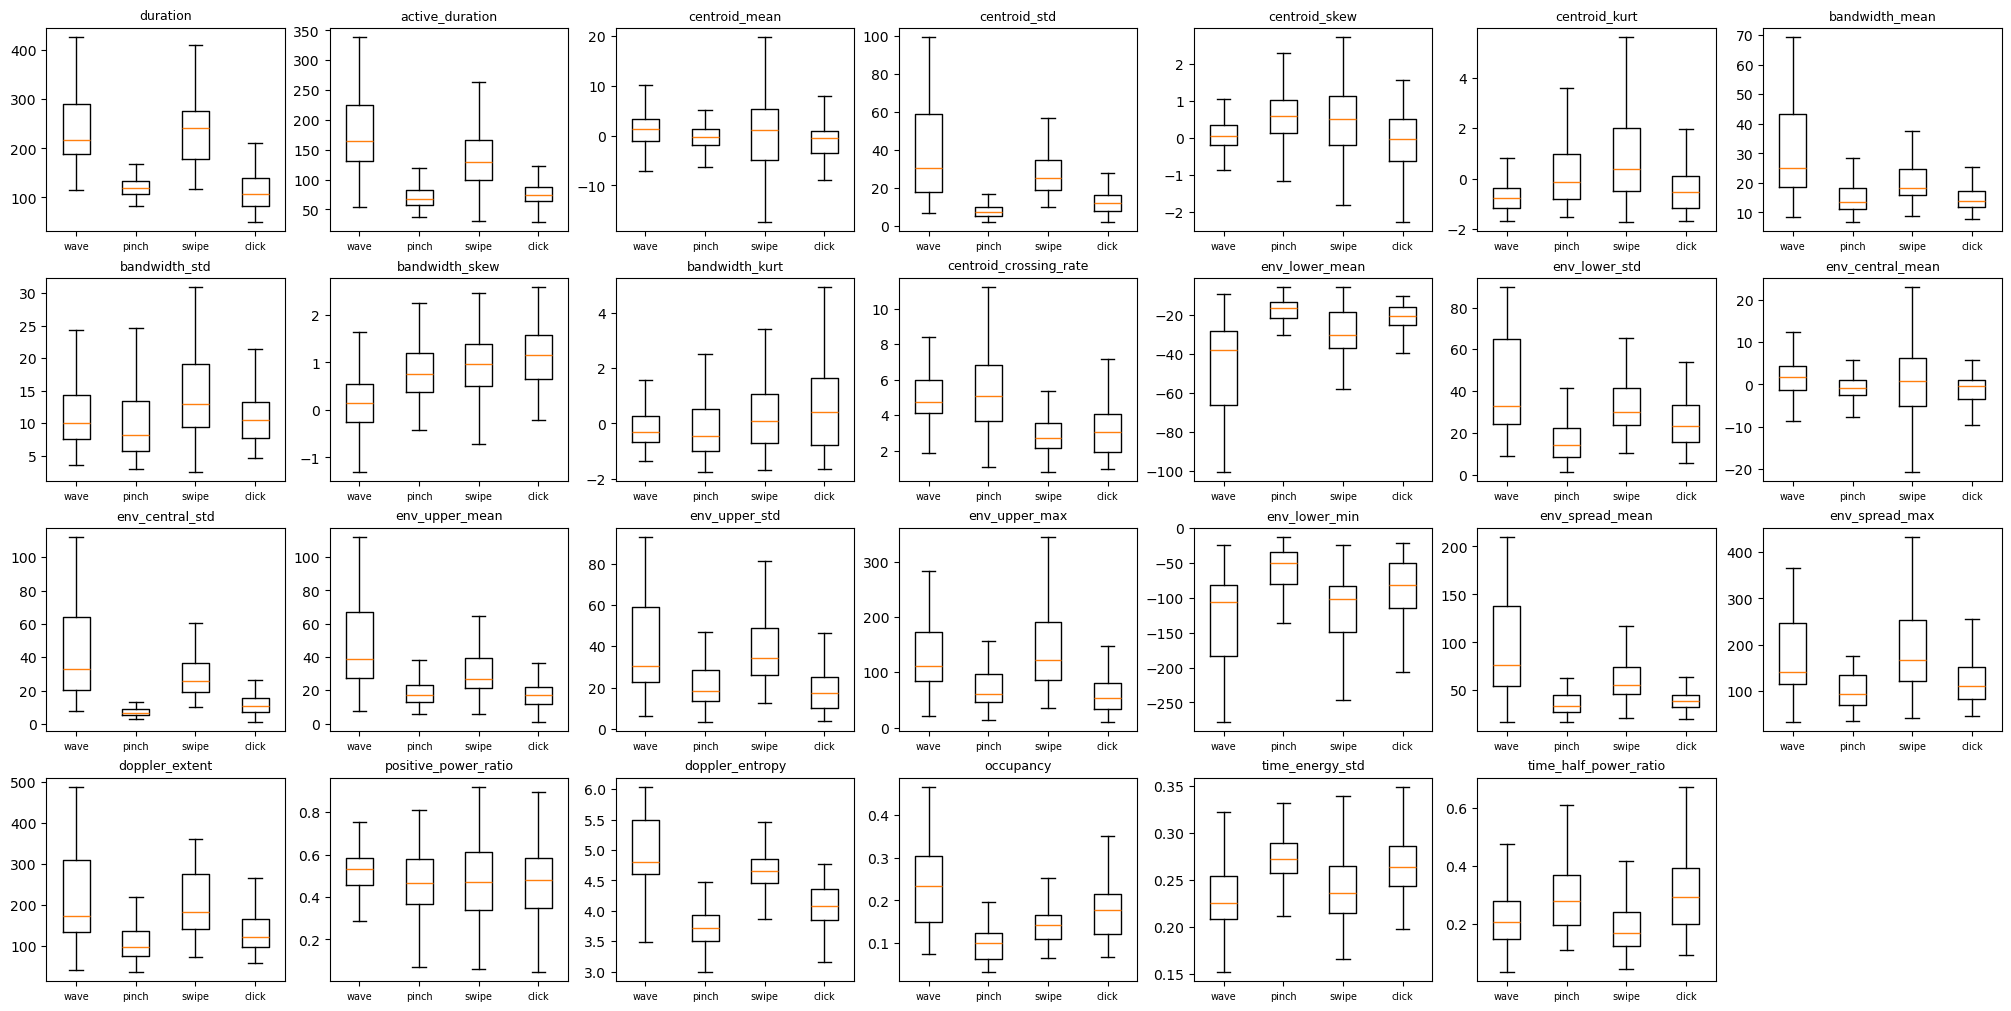

In [3]:
# All features for all samples (same function as prepare_data.py)
features = pd.DataFrame([F.extract_features(x) for x in spectrograms])
data = np.load(OUT_DIR / "wicos_dataset.npz", allow_pickle=True)
print(f"{features.shape[1]} features; same as X_feat in wicos_dataset.npz: "
      f"{np.allclose(features.to_numpy(np.float32), data['X_feat']) and list(features) == list(data['feature_names'])}")

# Distribution per gesture (training samples)
feat_train = features.iloc[idx_train]
fig, axes = plt.subplots(4, 7, figsize=(20, 10), constrained_layout=True)
for ax, name in zip(axes.ravel(), features.columns):
    ax.boxplot([feat_train[name][y_train == k] for k in range(len(GESTURES))], showfliers=False)
    ax.set_xticks(range(1, len(GESTURES) + 1), GESTURES, fontsize=7)
    ax.set_title(name, fontsize=9)
for ax in axes.ravel()[features.shape[1]:]:
    ax.axis("off")
fig.savefig(FIG_DIR / "feature_boxplots.pdf", bbox_inches="tight")
plt.show()

## Critical check: which features can be used?
A feature is only useful if it describes the **gesture**, and keeps doing so for a person the model has never seen. Each feature is checked on the training samples on four points:

1. **Gesture vs person:** the share of the (rank) variance of the feature that is explained by the gesture ($\eta^2_\text{gesture}$) and by the person ($\eta^2_\text{person}$). A feature that varies more with the person than with the gesture mainly identifies *who* made the gesture.
2. **Single-feature accuracy:** a small decision tree (depth 3) on only this feature, with 5-fold CV and with LOSO. A large drop from 5-fold to LOSO means the feature works for known persons but not for new ones. (Chance level: 0.25.)
3. **Robustness to the noise margin:** the rank correlation between the feature computed with the chosen margin (7.9 dB) and with a 3 dB higher margin. A feature that changes a lot depends on the exact noise threshold rather than on the gesture.
4. **Redundancy:** pairs of features with a rank correlation above 0.9 carry (almost) the same information.

In [4]:
def eta2(values, groups):
    """Share of the rank variance explained by the groups (one-way, on ranks)."""
    r = rankdata(values)
    return sum((groups == g).sum() * (r[groups == g].mean() - r.mean()) ** 2 for g in np.unique(groups)) / ((r - r.mean()) ** 2).sum()

# The same 5 CV folds as the model notebooks, and LOSO on the training persons
cv5 = PredefinedSplit(cv_fold[idx_train])
loso = LeaveOneGroupOut()

# Features with a 3 dB higher noise margin, for the robustness check
features_alt = pd.DataFrame([F.extract_features(spectrograms[i], margin=NOISE_MARGIN + 3) for i in idx_train])

rows = {}
for name in features.columns:
    v = feat_train[name].to_numpy()
    tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    rows[name] = {
        "eta2 gesture": eta2(v, y_train),
        "eta2 person": eta2(v, groups_train),
        "person / gesture": eta2(v, groups_train) / eta2(v, y_train),
        "5-fold": cross_val_score(tree, v[:, None], y_train, cv=cv5).mean(),
        "LOSO": cross_val_score(tree, v[:, None], y_train, cv=loso, groups=groups_train).mean(),
        "margin robustness": spearmanr(v, features_alt[name])[0],
    }
check = pd.DataFrame(rows).T.sort_values("LOSO", ascending=False)
display(check.round(3).style.background_gradient(subset=["person / gesture"], cmap="Reds", vmin=0, vmax=1.5)
        .background_gradient(subset=["margin robustness"], cmap="Reds_r", vmin=0.6, vmax=1))

,eta2 gesture,eta2 person,person / gesture,5-fold,LOSO,margin robustness
duration,0.652000,0.092000,0.142000,0.620000,0.540000,1.000000
env_central_std,0.595000,0.147000,0.247000,0.540000,0.518000,0.973000
centroid_std,0.557000,0.189000,0.340000,0.534000,0.492000,0.971000
doppler_entropy,0.633000,0.106000,0.167000,0.560000,0.491000,0.988000
env_spread_mean,0.393000,0.229000,0.583000,0.487000,0.452000,0.843000
centroid_crossing_rate,0.293000,0.067000,0.230000,0.478000,0.447000,0.883000
active_duration,0.531000,0.043000,0.081000,0.507000,0.441000,0.986000
env_lower_std,0.234000,0.205000,0.874000,0.449000,0.419000,0.838000
bandwidth_skew,0.250000,0.051000,0.202000,0.417000,0.404000,0.862000
bandwidth_mean,0.282000,0.268000,0.950000,0.439000,0.392000,0.697000


In [5]:
# Redundant pairs: rank correlation above 0.9 (training samples)
corr = feat_train.corr(method="spearman").abs()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr) for b in corr.columns[i + 1:] if corr.loc[a, b] > 0.9]
display(pd.DataFrame(pairs, columns=["feature", "feature ", "|rank correlation|"]).sort_values("|rank correlation|", ascending=False).round(3))

,feature,feature,|rank correlation|
1,centroid_std,env_central_std,0.974
5,env_upper_std,env_upper_max,0.955
4,env_lower_std,env_lower_min,0.941
0,centroid_mean,env_central_mean,0.935
2,bandwidth_mean,env_spread_mean,0.912
3,bandwidth_std,env_spread_max,0.908


**Results of the single-feature check.**
- **Strongest and clean:** `duration`, `env_central_std`, `doppler_entropy`, `active_duration`, `centroid_std` and `centroid_crossing_rate` separate the gestures on their own (LOSO 0.44-0.54) and depend little on the person (person/gesture ratio ≤ 0.34) and on the noise margin (robustness ≥ 0.88).
- **Person-dominated** (person/gesture ratio > 1): `bandwidth_std` (4.1), `env_spread_max`, `centroid_mean`, `env_lower_min`, `env_upper_std`, `env_central_mean`. These vary more between persons than between gestures; their single-feature LOSO is close to chance (0.19-0.33).
- **Sensitive to the noise margin** (robustness < 0.76): `bandwidth_mean`, `bandwidth_std`, `env_spread_max`, `env_lower_min`. The bandwidth and the outer envelopes react to the weakest gesture pixels, exactly the ones that a different threshold adds or removes.
- **Near chance** with almost no gesture information ($\eta^2_\text{gesture}$ < 0.04): `positive_power_ratio` (all gestures move the hand towards and away from the radar about equally) and `bandwidth_kurt`.
- **Redundant pairs:** the centroid and the central envelope describe the same curve (`centroid_std` ≈ `env_central_std`, `centroid_mean` ≈ `env_central_mean`), the standard deviation of an outer envelope follows its extreme, and the mean bandwidth follows the mean envelope spread.
- `occupancy` and `doppler_extent` depend almost as much on the person as on the gesture (ratio 0.87 and 0.95): how many cells rise above the noise floor also depends on how noisy the recording is (Person B).

**`duration` needs care.** It is the strongest single feature, but it is the length of the *recording*: the length depends on the gesture (wave and swipe are long), but also on the person (see `data_exploration.ipynb`), and possibly on how the recordings were cut. `active_duration` only counts the time bins with gesture power, so it measures the gesture itself.

### Does removing the suspicious features help?
The single-feature check cannot see interactions: a feature that is weak or person-dependent on its own can still help in combination with others. The real test is the accuracy of the full models without the suspicious groups. Three models from the model notebooks (with default settings), 5-fold CV and LOSO accuracy on the training set:

In [6]:
suspicious = {
    "redundant": ["centroid_std", "env_upper_max", "env_lower_min", "env_central_mean", "bandwidth_mean", "env_spread_max"],
    "margin-sensitive": ["bandwidth_mean", "bandwidth_std", "env_spread_max", "env_lower_min"],
    "near chance": ["positive_power_ratio", "bandwidth_kurt"],
    "person-dominated": ["bandwidth_std", "env_spread_max", "centroid_mean", "env_lower_min", "env_upper_std", "env_central_mean"],
}
variants = {"all 27": []} | {f"without {k}": v for k, v in suspicious.items()}
variants["without all of the above"] = sorted(set(sum(suspicious.values(), [])))
variants["without duration"] = ["duration"]
variants["without duration and active_duration"] = ["duration", "active_duration"]

models = {
    "LR": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "SVM": lambda: make_pipeline(StandardScaler(), SVC()),
    "RF": lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}
rows = {}
for variant, dropped in variants.items():
    X = feat_train.drop(columns=dropped).to_numpy()
    rows[variant] = {"features": X.shape[1]}
    for m, make in models.items():
        rows[variant][f"{m} 5-fold"] = cross_val_score(make(), X, y_train, cv=cv5).mean()
        rows[variant][f"{m} LOSO"] = cross_val_score(make(), X, y_train, cv=loso, groups=groups_train).mean()
pruning = pd.DataFrame(rows).T
display(pruning.round(3))

,features,LR 5-fold,LR LOSO,SVM 5-fold,SVM LOSO,RF 5-fold,RF LOSO
all 27,27.0,0.931,0.783,0.956,0.772,0.939,0.759
without redundant,21.0,0.921,0.771,0.954,0.764,0.944,0.760
without margin-sensitive,23.0,0.927,0.776,0.957,0.780,0.939,0.760
without near chance,25.0,0.934,0.788,0.951,0.777,0.936,0.750
without person-dominated,21.0,0.928,0.784,0.953,0.771,0.940,0.749
without all of the above,16.0,0.926,0.777,0.943,0.742,0.941,0.745
without duration,26.0,0.921,0.734,0.940,0.751,0.934,0.736
without duration and active_duration,25.0,0.865,0.693,0.911,0.693,0.901,0.697


**Results.**
- **Removing the suspicious groups does not improve the models.** Every pruned variant stays within about ±0.02 of the full set, for 5-fold CV and LOSO, which is within the variation between the 6 LOSO folds. The features that look weak on their own still add a little in combination (removing all 13 lowers the SVM LOSO from 0.772 to 0.742).
- **The duration features matter most:** without `duration` the LOSO accuracy drops by 0.02-0.05, without both duration features by 0.07-0.09.

**Conclusion.** All 27 features are kept in the dataset (`X_feat`); feature selection, if any, is done inside the cross-validation of the model notebooks (e.g. L1 regularisation in the logistic regression), not here. The one feature that has to be justified in the report is `duration`: if the recording length is set by how the dataset was recorded rather than by the gesture, it partly learns the recording procedure. `active_duration` is the safer alternative.